# Superdense coding, send message 00

In [54]:
from qiskit import *
from qiskit.visualization import plot_bloch_multivector, visualize_transition, plot_histogram
from qiskit.visualization import array_to_latex
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import Operator

In [55]:
message = input("Enter the message (00, 01, 10, or 11): ")
if message in ("00", "01", "10", "11"):
    print("Your message is:", message)
else:
    print("Invalid message. Please enter 00, 01, 10, or 11.")

Your message is: 11


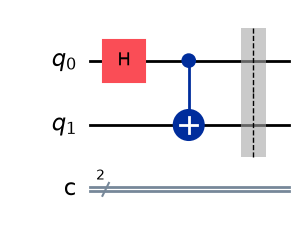

In [56]:
# Step 1: Create a Entangled Quantum Circuit
qc = QuantumCircuit(2, 2)
qc.h(0)  # apply the gate to the first qubit (index = 0)
qc.cx(0,1)  # apply the gate to the first qubit (index
qc.barrier()  # add a barrier to separate Bob's decoding from the rest of the circuit
qc.draw('mpl')

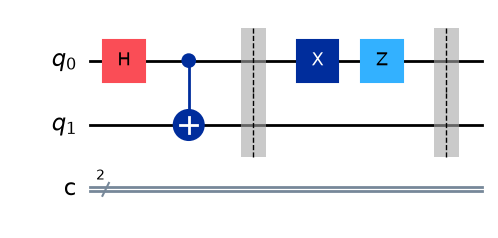

In [57]:
# Step 2: Alice encodes her message by applying a quantum gate to her qubit (the first qubit in the circuit). The message is represented by a 2-bit binary string, which can be one of the following: '00', '01', '10', or '11'. Depending on the message, Alice applies a specific quantum gate to her qubit:
# - If the message is '00', Alice does nothing (applies the identity gate).
# - If the message is '01', Alice applies the Pauli-X gate (also known as the NOT gate) to her qubit.
# - If the message is '10', Alice applies the Pauli-Z gate to her qubit.
# - If the message is '11', Alice applies the Pauli-XZ gate to her qubit.    

if message == '00':
    qc.id(0)  # apply the identity gate to the first qubit (index = 0)
elif message == '01':
    qc.x(0)  # apply the X gate to the first qubit (index = 0)
elif message == '10':
    qc.z(0)  # apply the Z gate to the first qubit (index = 0)
elif message == '11':
    qc.x(0)  # apply the X gate to the first qubit (index = 0)
    qc.z(0)  # apply the Z gate to the first qubit (index = 0)

# Alice does nothing for message '00'
# qc.id(0)  

# For sending 10, Alice applies Z gate to her qubit
# qc.z(0)  # apply the Z gate to the first qubit (index

# For sending 11, Alice applies XZ gate to her qubit
# qc.x(0)  # apply the X gate to the first qubit (index = 0)
# qc.z(0)  # apply the Z gate to the first qubit (index = 0)

qc.barrier()  # add a barrier to separate Alice's encoding from the rest of the circuit
qc.draw('mpl')

In [58]:
# Step 3: Bob decodes the message.
# Bob decodes the message by applying a series of quantum gates to the qubits in the circuit. The decoding process involves the following steps:
# - Bob applies a CNOT gate to the qubits, with the first qubit as the control and the second qubit as the target.
# - Bob applies a Hadamard gate to the first qubit.
qc.cx(0, 1)  # apply the CNOT gate
qc.h(0)  # apply the Hadamard gate  
qc.barrier()  # add a barrier to separate Bob's decoding from the rest of the circuit
# qc.draw('mpl')
print(qc.draw('text'))


     ┌───┐      ░ ┌───┐┌───┐ ░      ┌───┐ ░ 
q_0: ┤ H ├──■───░─┤ X ├┤ Z ├─░───■──┤ H ├─░─
     └───┘┌─┴─┐ ░ └───┘└───┘ ░ ┌─┴─┐└───┘ ░ 
q_1: ─────┤ X ├─░────────────░─┤ X ├──────░─
          └───┘ ░            ░ └───┘      ░ 
c: 2/═══════════════════════════════════════
                                            


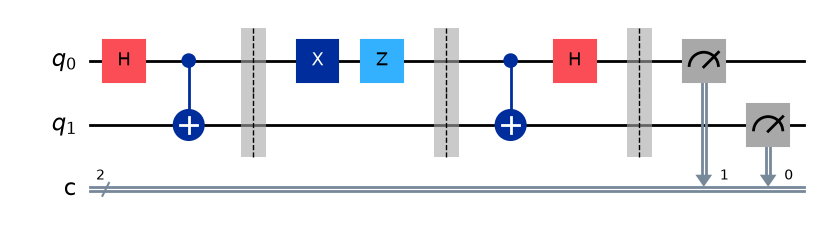

In [59]:
# Step 4: Measure the qubits to obtain the classical bits.

# qc.measure([0, 1], [0, 1])  
qc.measure([0, 1], [1, 0]) # it prints classical bits in reverse order, so we need to swap the order of the classical bits in the measurement operation.  
qc.draw('mpl')

{'11': 1024}


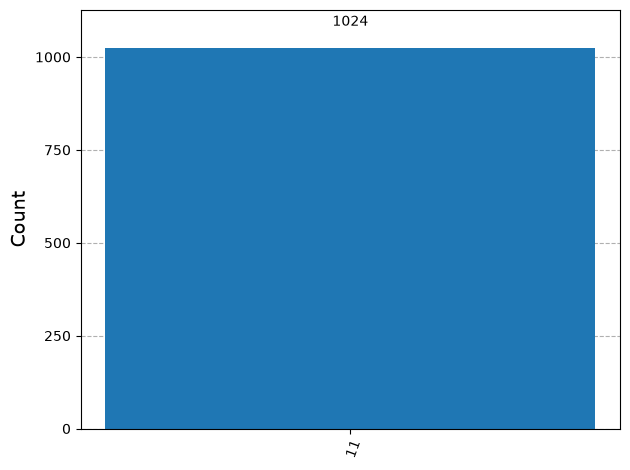

In [60]:
simulator = AerSimulator()
compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()
print(result.get_counts())
plot_histogram(result.get_counts())